# Predicting an Arsenal Player's Position from Their Match Statistics

#### Saidmasrurkhon Mansuri

**Abstract.** I wanted to know if the statistics of one match (tackles, shots, passes and so on) are enough to tell if a player is a defender, a midfielder or a forward. I used a public dataset of Arsenal matches from 2017/18 to February 2023, with 2,741 player appearances. I explored the data with tables and charts, kept the players who played at least 45 minutes (2,164 appearances), and compared a baseline, a logistic regression and a random forest. Both real models predict the position correctly in about 72 to 73% of the cases on a test set, against 40.4% for the baseline. Forwards are the easiest position to recognize and midfielders are the hardest.

In [1]:
# libraries for the whole project
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')   # hides some warnings that are not important here
sns.set_theme(style='whitegrid')

# same order and same colors for the three positions in every chart
line_order = ['Defender', 'Midfielder', 'Forward']
line_colors = sns.color_palette('Set2', 3)

## Table of Content

[Problem](#problem)   
[Data Understanding](#data_understanding)   
[Data Preparation](#data_preparation)   
[Modeling](#modeling)   
[Evaluation](#evaluation)   
[References](#references)

## Problem <a class="anchor" id="problem"></a>

In football, a defender, a midfielder and a forward do different things during a match: defenders tackle and block, forwards shoot, and midfielders pass and move the ball forward. If that is true, the numbers of a single match should be enough to guess the position of a player without seeing his name or where he stood on the pitch.

**Questions**
1. Which match statistics are different between defenders, midfielders and forwards?
2. How accurately can a simple model predict the position of a player from his statistics, compared with just guessing the most common position?
3. Which positions does the model mix up, and which statistics help the most?

This is a **classification problem with three classes** (Defender, Midfielder, Forward). I judge the models with accuracy and macro F1 score on a test set that is not used for training.

## Data Understanding<a class="anchor" id="data_understanding"></a>

The data comes from the kaggle **Arsenal EPL (2017/18 - 2022/23)** by Rustem Nagimov. It has three csv files with Arsenal Premier League matches from the 2017/18 season until February 2023: `matches.csv` (one row per match), `players.csv` (one row per player in each match) and `goalkeepers.csv` (one row per goalkeeper in each match). According to the author, the numbers were collected from transfermarkt, flashscore and fbref.com.

For this project I only need **`players.csv`**. Each row is one player in one match, with his position and statistics such as minutes played, goals, shots, tackles, interceptions, passes and expected goals (xG). The column `Line` tells if the player is a Defender, a Midfielder or a Forward, and this is what I want to predict. Goalkeepers are in a different file, so they are not part of this problem.

In [2]:
# the csv file is read directly from the GitHub repository
data_url = 'https://raw.githubusercontent.com/bokushiSan/Arsenal_EPL_dataset/main/players.csv'
players = pd.read_csv(data_url)

print('rows and columns:', players.shape)

# first 5 rows, transposed so that all 28 columns fit on the screen
players.head().T

rows and columns: (2741, 28)


,0,1,2,3,4
LastName,Aubameyang,Bellerin,Holding,Iwobi,Kolasinac
FirstName,Pierre-Emerick,Hector,Rob,Alex,Sead
Date,2018-05-13,2018-05-13,2018-05-13,2018-05-13,2018-05-13
Start,1,1,1,1,1
Pos,LW,RB,CB,RM,LB
Min,66.0,90.0,90.0,71.0,67.0
G,1.0,0.0,0.0,0.0,0.0
A,0.0,0.0,0.0,0.0,0.0
PK,0.0,0.0,0.0,0.0,0.0
PKA,0.0,0.0,0.0,0.0,0.0


### Tables: data quality and summary

In [3]:
# are there missing values or repeated rows?
print('missing values   :', players.isnull().sum().sum())
print('repeated rows    :', players.duplicated(['LastName', 'FirstName', 'Date']).sum())
print('different players:', players.groupby(['LastName', 'FirstName']).ngroups)
print('different matches:', players['Date'].nunique())

missing values   : 0
repeated rows    : 0
different players: 56
different matches: 214


In [4]:
# the match statistics that I will use as features
stats = ['Min', 'G', 'A', 'S', 'SoT', 'Touches', 'Tackles', 'Ints', 'Blocks',
         'xG', 'npxG', 'xAG', 'Passes', 'PassesA', 'PrgPas', 'Carries', 'PrgCar']

players[stats].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Min,2741.0,69.55,29.48,1.0,55.0,90.0,90.0,90.0
G,2741.0,0.13,0.38,0.0,0.0,0.0,0.0,3.0
A,2741.0,0.09,0.32,0.0,0.0,0.0,0.0,3.0
S,2741.0,1.04,1.31,0.0,0.0,1.0,2.0,8.0
SoT,2741.0,0.35,0.65,0.0,0.0,0.0,1.0,5.0
Touches,2741.0,50.07,28.68,0.0,27.0,51.0,71.0,141.0
Tackles,2741.0,1.14,1.26,0.0,0.0,1.0,2.0,9.0
Ints,2741.0,0.72,1.03,0.0,0.0,0.0,1.0,7.0
Blocks,2741.0,0.78,0.99,0.0,0.0,0.0,1.0,6.0
xG,2741.0,0.12,0.26,0.0,0.0,0.0,0.1,3.0


The data is very clean: there are no missing values and no repeated rows. It has 56 different players and 214 matches. The statistics are counts per match, so most values are small numbers (a player has 0 or 1 goals in a match, for example). The minutes played go from 1 to 90, and the median is 90.

The table below shows how the detailed position (`Pos`) is related to `Line`.

In [5]:
# detailed position vs the three lines
pd.crosstab(players['Pos'], players['Line'])

Line,Defender,Forward,Midfielder
Pos,,,
AM,0,0,239
CB,525,0,0
CM,0,0,223
DM,0,0,267
FW,0,335,0
LB,205,0,0
LM,0,0,111
LW,0,225,0
RB,203,0,0


Every detailed position belongs to exactly one line (CB, LB, RB and WB are defenders, and so on). That means `Pos` already contains the answer, so I **cannot use it as a feature**, because the model would only copy it. I will use only the match statistics.

### Charts

**Chart 1: how many appearances for each position?**

,rows,percent
Line,,
Defender,1001,36.5
Midfielder,956,34.9
Forward,784,28.6


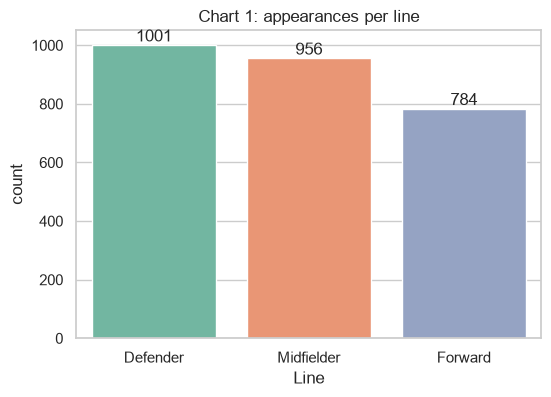

In [6]:
# chart 1: number of rows of each line, and table with percentages
line_counts = players['Line'].value_counts().loc[line_order]
display(pd.DataFrame({'rows': line_counts, 'percent': (line_counts / len(players) * 100).round(1)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=players, x='Line', order=line_order, palette=line_colors)

# newer seaborn makes one container per bar, so I loop over all of them to label every bar
for container in ax.containers:
    ax.bar_label(container)

plt.title('Chart 1: appearances per line')
plt.show()

The three classes are not perfectly balanced but they are close: defenders are the biggest group (36.5%) and forwards the smallest (28.6%). A model that always answers "Defender" would be right about 36.5% of the time at this point, so that is the number to beat (it changes a little after the filter that I apply in Data Preparation).

**Chart 2: minutes played.**

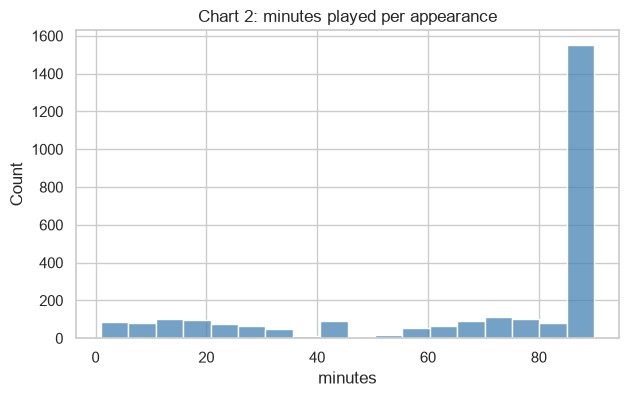

appearances with less than 45 minutes: 577 of 2741


In [7]:
# chart 2: histogram of the minutes played
plt.figure(figsize=(7, 4))
sns.histplot(players['Min'], bins=18, color='steelblue')
plt.title('Chart 2: minutes played per appearance')
plt.xlabel('minutes')
plt.show()

print('appearances with less than 45 minutes:', (players['Min'] < 45).sum(), 'of', len(players))

Most players played the full 90 minutes, but there is a long tail of substitutes with very few minutes (some only 1 or 2). In 10 minutes a player does not have many chances to tackle or to shoot, so these rows will be noisy. I will deal with this in the Data Preparation section.

**Chart 3: do the three lines have different statistics?**

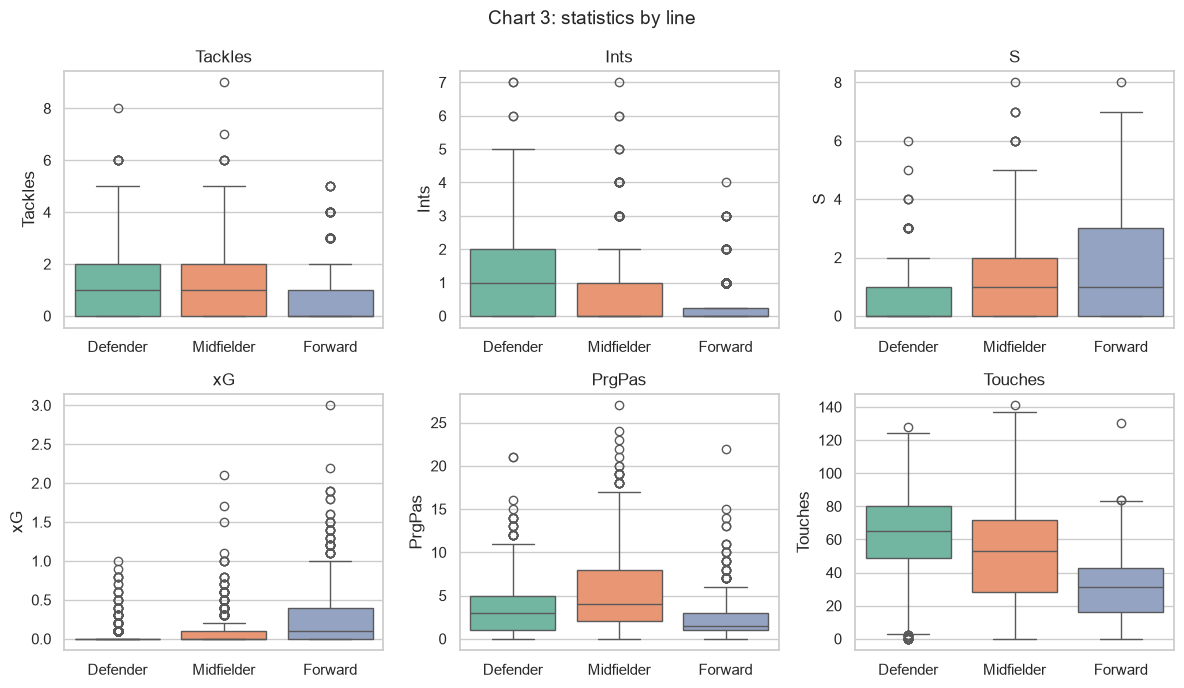

In [8]:
# chart 3: boxplots of six statistics for every line
box_stats = ['Tackles', 'Ints', 'S', 'xG', 'PrgPas', 'Touches']

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), box_stats):
    sns.boxplot(data=players, x='Line', y=col, order=line_order, palette=line_colors, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Chart 3: statistics by line', fontsize=14)
plt.tight_layout()
plt.show()

There are clear differences:
- **Defenders** have the highest boxes for interceptions and touches, and defenders and midfielders both make more tackles than forwards.
- **Forwards** have the highest boxes for shots and for xG (up to 3), but far fewer touches.
- **Midfielders** are the highest in progressive passes (`PrgPas`), which are passes that move the ball forward in a significant way.

Many boxes overlap though, so no single statistic is enough, and the midfielders are in the middle of the other two groups in almost everything.

**Chart 4: relation between the statistics.**

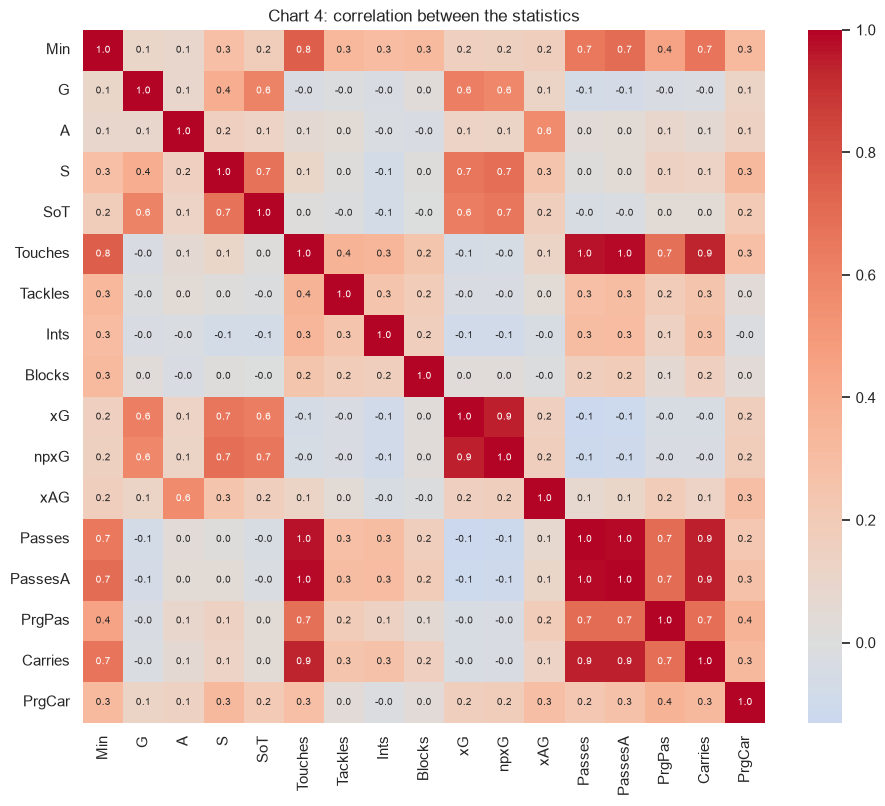

In [9]:
# chart 4: correlation heatmap of the statistics
plt.figure(figsize=(11, 9))
sns.heatmap(players[stats].corr(), annot=True, fmt='.1f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Chart 4: correlation between the statistics')
plt.show()

Some statistics move together almost perfectly: touches, passes and attempted passes (all close to 1.0 in the chart), and xG and non-penalty xG (0.9). It makes sense, because a player who touches the ball more also passes more. This is not a problem for the models I use, but it means I should not read too much into the importance of each of these individual columns later.

**Chart 5: passes and xG together.**

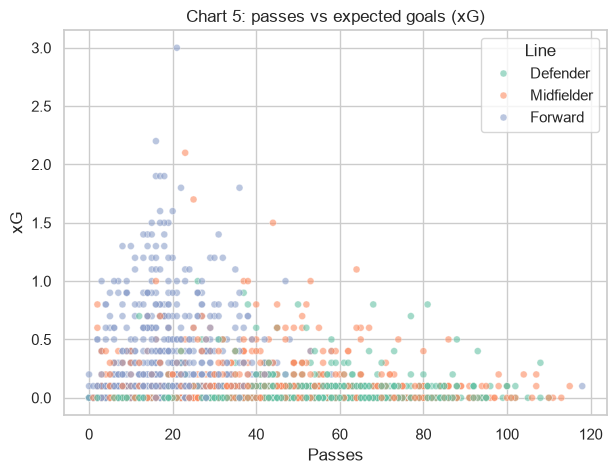

In [10]:
# chart 5: scatter plot of passes vs xG, each point is one appearance
plt.figure(figsize=(7, 5))
sns.scatterplot(data=players, x='Passes', y='xG', hue='Line', hue_order=line_order,
                palette=line_colors, alpha=0.6, s=25)
plt.title('Chart 5: passes vs expected goals (xG)')
plt.show()

Forwards are mostly on the left side (few passes) and they have the highest xG values, up to 3. Defenders are more to the right (many passes) with almost no xG. Midfielders overlap with both and are spread between the two. Even two statistics together separate forwards from defenders quite well, so I expect a model with all the statistics to do well, but not perfectly, because of the midfielders.

**Chart 6: how many shots, tackles and passes on average?**

,S,Tackles,Ints,PrgPas,PrgCar
Line,,,,,
Defender,0.53,1.39,1.03,3.60,1.29
Midfielder,1.02,1.16,0.72,5.33,1.77
Forward,1.71,0.81,0.32,2.16,2.05


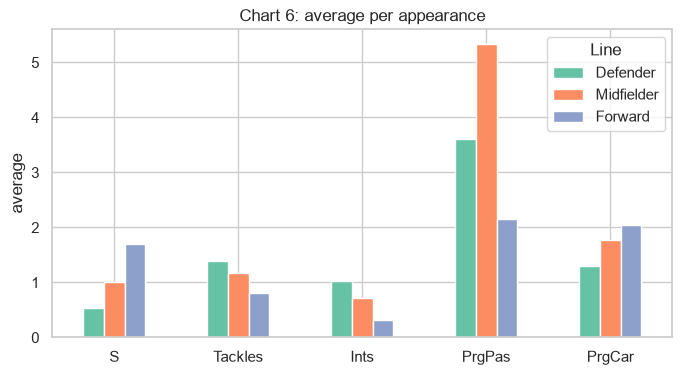

In [11]:
# chart 6: average of some statistics for each line (table + bar chart)
means = players.groupby('Line')[['S', 'Tackles', 'Ints', 'PrgPas', 'PrgCar']].mean().loc[line_order]
display(means.round(2))

means.T.plot(kind='bar', figsize=(8, 4), color=line_colors)
plt.title('Chart 6: average per appearance')
plt.xticks(rotation=0)
plt.ylabel('average')
plt.show()

The table confirms the previous charts: forwards have the most shots (1.71 per match, against 0.53 for defenders) and progressive carries, defenders have the most tackles and interceptions (1.39 and 1.03, against 0.81 and 0.32 for forwards), and midfielders have the most progressive passes (5.33).

## Data Preparation<a class="anchor" id="data_preparation"></a>

The data is already clean, so there is not much to fix. These are the steps I follow:

1. **Keep players with at least 45 minutes.** As seen in Chart 2, players with just a few minutes have almost no actions in their row, so their position cannot be seen in the numbers. I use 45 minutes (half a match) as the limit. This is my own choice and I did not try to optimize it.
2. **Choose the features.** I use the 17 match statistics. I do not use `Pos` (it contains the answer), the names, the date, `Start` or `C` (captain), because they say nothing about how the player played.
3. **Split into train and test.** 80% of the rows for training and 20% for the final test. I use `stratify` so the three positions have the same share in both parts, and `random_state=42` so the split is always the same.
4. **Scaling.** Logistic regression works better when the columns are on the same scale, so I put a `StandardScaler` inside the model pipeline. This way the scaler learns only from the training data. The random forest does not need scaling.

In [12]:
# step 1: keep only the players who played at least half a match
df = players[players['Min'] >= 45].copy()
print('appearances before:', len(players), '| after:', len(df))

# step 2: features and target
X = df[stats]
y = df['Line']

# the share of each line after the filter
(y.value_counts(normalize=True).loc[line_order] * 100).round(1).to_frame('percent')

appearances before: 2741 | after: 2164


,percent
Line,
Defender,40.4
Midfielder,33.8
Forward,25.8


In [13]:
# step 3: train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('training rows:', len(X_train), '| test rows:', len(X_test))

training rows: 1731 | test rows: 433


## Modeling<a class="anchor" id="modeling"></a>

I compare three models. I keep them simple on purpose and I use the default parameters of scikit-learn, except for the ones shown here.

| Model | Why | Parameters |
|---|---|---|
| Baseline (DummyClassifier) | always answers the most common position, so I know what "better than nothing" is | `strategy='most_frequent'` |
| Logistic regression | simple model that is easy to understand | scaled data, `max_iter=2000` |
| Random forest | many decision trees voting together, can find more complex patterns | `n_estimators=200` |

To compare them I use **5-fold cross validation on the training set**: the training data is split in 5 parts, the model is trained on 4 and tested on the other one, 5 times. The average is more reliable than a single split. The test set is not used here.

In [14]:
models = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random forest': RandomForestClassifier(n_estimators=200, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    model.fit(X_train, y_train)     # also train on the full training set, needed for the test later
    rows.append({'model': name, 'cv accuracy': scores.mean(), 'cv std': scores.std()})

cv_table = pd.DataFrame(rows).set_index('model')
cv_table.round(3)

,cv accuracy,cv std
model,,
Baseline (most frequent),0.404,0.001
Logistic regression,0.717,0.029
Random forest,0.712,0.033


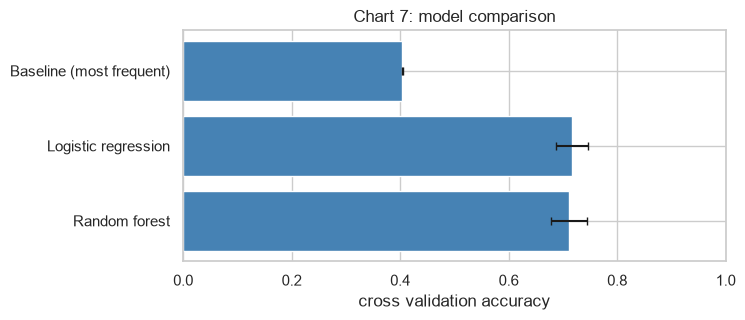

In [15]:
# chart 7: cross validation accuracy of the three models
plt.figure(figsize=(7, 3))
plt.barh(cv_table.index, cv_table['cv accuracy'], xerr=cv_table['cv std'], color='steelblue', capsize=3)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.xlabel('cross validation accuracy')
plt.title('Chart 7: model comparison')
plt.show()

The baseline reaches about 40.4%, which is the share of the most common position. Logistic regression (71.7%) and the random forest (71.2%) are much better and very close to each other. The difference between them is smaller than the standard deviation between folds, so I cannot say that one is better than the other.

## Evaluation<a class="anchor" id="evaluation"></a>

Now I use the **test set** for the first time, with data that no model has seen.

In [16]:
# accuracy and macro F1 of the three models on the test set
test_rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    test_rows.append({'model': name,
                      'test accuracy': accuracy_score(y_test, pred),
                      'test macro F1': f1_score(y_test, pred, average='macro')})

test_table = pd.DataFrame(test_rows).set_index('model')
test_table.round(3)

,test accuracy,test macro F1
model,,
Baseline (most frequent),0.404,0.192
Logistic regression,0.730,0.730
Random forest,0.721,0.717


The test results agree with the cross validation: the baseline gets 40.4%, logistic regression 73.0% and the random forest 72.1%. So the models predict the position correctly about 7 times out of 10, almost twice as often as the baseline. I use the model with the best cross validation accuracy (logistic regression) for the details below.

### Where does the best model make mistakes?

In [17]:
# the best real model according to the cross validation
best_name = cv_table.drop('Baseline (most frequent)')['cv accuracy'].idxmax()
best_model = models[best_name]
y_pred = best_model.predict(X_test)
print('best model:', best_name)

# precision, recall and F1 for each position
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).T
report.loc[line_order + ['accuracy', 'macro avg']].round(3)

best model: Logistic regression


,precision,recall,f1-score,support
Defender,0.773,0.760,0.767,175.00
Midfielder,0.664,0.623,0.643,146.00
Forward,0.742,0.821,0.780,112.00
accuracy,0.730,0.730,0.730,0.73
macro avg,0.726,0.735,0.730,433.00


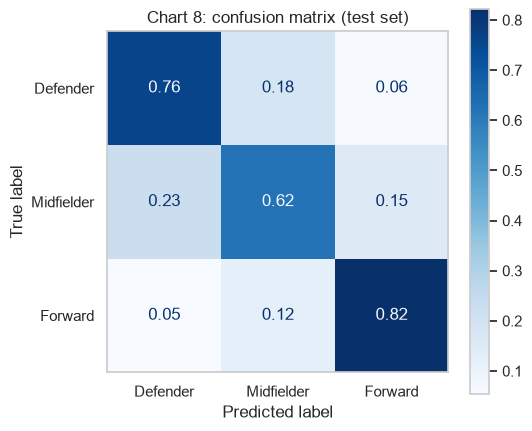

In [18]:
# chart 8: confusion matrix, each row adds up to 1 (the diagonal is the recall of each position)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=line_order, normalize='true',
                                        cmap='Blues', values_format='.2f', ax=ax)
ax.grid(False)
ax.set_title('Chart 8: confusion matrix (test set)')
plt.show()

The model recognizes **forwards** best (82% of them are found, F1 of 0.78) and **defenders** next (76% found, F1 of 0.77). **Midfielders** are the hardest: only 62% are found (F1 of 0.64). In the confusion matrix, the mistakes are between neighbors on the pitch: 23% of the midfielders are predicted as defenders and 15% as forwards, and 18% of the defenders are predicted as midfielders. Defenders and forwards are almost never mixed up (5% and 6%). It makes sense, because a midfielder does a bit of what defenders do (tackles and passes) and a bit of what forwards do (shots and carries), so his numbers are in the middle.

### Which statistics matter the most?

The random forest can tell how much it uses each column (feature importance), so I use it to answer the third question.

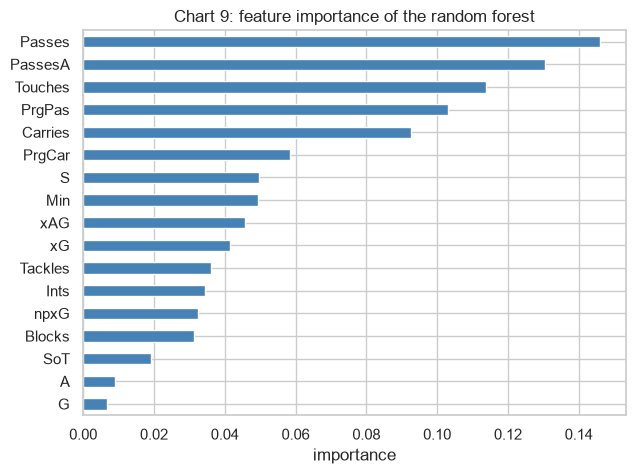

In [19]:
# chart 9: feature importance of the random forest
rf = models['Random forest']
importance = pd.Series(rf.feature_importances_, index=stats).sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind='barh', color='steelblue')
plt.title('Chart 9: feature importance of the random forest')
plt.xlabel('importance')
plt.show()

The most important columns are all about how much a player is involved with the ball: passes, attempted passes, touches, progressive passes and carries (the top four add up to about 49% of the importance). Defenders and midfielders touch and pass the ball much more than forwards, and the model uses this to separate them. Shots, minutes, xG and xAG are in the middle. Goals and assists are the least useful columns, probably because they are very rare (most players have 0 in a match), so they say almost nothing about the position. As seen in Chart 4, passes, attempted passes and touches are almost the same information, so the importance is shared between them, and the group is more important than any single column.

### Conclusions

- **Question 1 (what is different):** The three positions have different profiles. Defenders have the most tackles, interceptions and touches, forwards have the most shots and the highest xG with few touches, and midfielders have the most progressive passes.
- **Question 2 (how accurate):** Logistic regression and the random forest predict the position of a player in about 72% to 73% of the cases on new data, against 40.4% for the baseline. They are very close to each other, so the simple logistic regression is enough for this problem.
- **Question 3 (mistakes and important statistics):** Midfielders are the hardest position (62% found) and most of the mistakes are with the neighbor positions. The models rely mostly on passes, touches and carries, and almost not on goals or assists.

**Limitations.** 
- Each row has only the statistics of one match, and a player can have an unusual match.
- The limit of 45 minutes was my own decision, and it removes about a fifth of the data (577 of 2,741 appearances), so the results are for players who played at least half a match.
- The same 56 players are in the training and in the test set (in different matches), so the test accuracy could be a bit optimistic for a completely new player. I did not test this.
- It is only one club, so the results could be different for other teams.
- The test set is small (433 rows), so a difference of one or two points between the models is not meaningful.

**Ideas for the future.** I can try the detailed positions (CB, LB, AM, ...) instead of the three lines, add the goalkeepers file, use statistics per 90 minutes, or test the model with players from another team.

## References<a class="anchor" id="references"></a>

- Nagimov, R. (2022). Arsenal  EPL (2017/18 - 2022/23). https://www.kaggle.com/datasets/rustemnagimov/arsenal-epl-dataset
- Data file used in this notebook: https://raw.githubusercontent.com/bokushiSan/Arsenal_EPL_dataset/main/players.csv
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830. https://scikit-learn.org/stable/user_guide.html
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95.
- Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.

**Disclaimer!** <font color='grey'>This notebook was prepared by [Your Name] as a term project. The notebook is available for educational purposes only. There is no guarantee on the correctness of the content provided as it is a student work.
</font>